# Entregable [N] – Clasificación de Credit Score con Árbol de Decisión

**Asignatura:** Machine Learning 1 
**Autora:** Taisiia Bogatyreva

## Objetivo
1. Clasificar el puntaje crediticio de los clientes (Good, Standard, Poor) del conjunto *Credit Score Classification* mediante un árbol de decisión.
2. Limpiar y transformar los datos (valores numéricos guardados como texto, valores faltantes, valores atípicos y variables categóricas).
3. Aplicar validación cruzada estratificada de 5 folds, calcular las métricas de clasificación y generar la matriz de confusión.
4. Documentar las decisiones tomadas y las conclusiones.

## Datos
- **Fuente:** [Kaggle – Credit Score Classification](https://www.kaggle.com/datasets/parisrohan/credit-score-classification)
- **Archivo utilizado:** `train.csv` (`test.csv` no se usa porque no contiene la variable objetivo)
- **Variable objetivo:** `Credit_Score`
- **Filas:** 100 000

## Metodología
La validación cruzada, las métricas y la matriz de confusión se calculan dentro de la función `analizar` (ver `src/evaluacion.py`).

In [1]:
import sys; sys.path.append("..")
import pandas as pd
from common.evaluacion import analizar, revisar_datos

In [2]:
# Чтение данных train
df = pd.read_csv("data/credit-score-classifier/train.csv")
revisar_datos(df)
print("\nDistribución de clases:")
print(df["Credit_Score"].value_counts())

/var/folders/gr/08bfj0c54m3fzt4__chtyglr0000gn/T/ipykernel_88973/4227599861.py:2: DtypeWarning: Columns (26: Monthly_Balance) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/credit-score-classifier/train.csv")


Dimensiones: (100000, 28)
Total de valores nulos: 60071
Filas completamente duplicadas: 0

--- Tipos de datos ---
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  str    
 1   Customer_ID               100000 non-null  str    
 2   Month                     100000 non-null  str    
 3   Name                      90015 non-null   str    
 4   Age                       100000 non-null  str    
 5   SSN                       100000 non-null  str    
 6   Occupation                100000 non-null  str    
 7   Annual_Income             100000 non-null  str    
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,100000,100000,0x1602,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_ID,100000,12500,CUS_0xd40,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month,100000,8,January,12500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,90015,10139,Langep,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,100000,1788,38,2833,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SSN,100000,12501,#F%$D@*&8,5572,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,100000,16,_______,7062,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Annual_Income,100000,18940,17273.83,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Monthly_Inhand_Salary,84998.0,NaN,NaN,NaN,4194.17085,3183.686167,303.645417,1625.568229,3093.745,5957.448333,15204.633333
Num_Bank_Accounts,100000.0,NaN,NaN,NaN,17.09128,117.404834,-1.0,3.0,6.0,7.0,1798.0



Distribución de clases:
Credit_Score
Standard    53174
Poor        28998
Good        17828
Name: count, dtype: int64


In [3]:
def limpiar_credito(df):
    # Columnas identificadoras o de texto libre
    df = df.drop(columns=["ID", "Customer_ID", "Month", "Name", "SSN",
                          "Type_of_Loan", "Credit_History_Age"], errors="ignore")

    # Números guardados como texto con basura (p. ej. "23_")
    cols_num = ["Age", "Annual_Income", "Num_of_Loan", "Num_of_Delayed_Payment",
                "Changed_Credit_Limit", "Outstanding_Debt",
                "Amount_invested_monthly", "Monthly_Balance"]
    for col in cols_num:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col].astype(str).str.replace("_", ""),
                                    errors="coerce")

    # Edades inválidas (p. ej. 8000 o negativas)
    df = df[(df["Age"] > 0) & (df["Age"] < 100)].copy()

    # Valores faltantes numéricos: mediana
    num_cols = df.select_dtypes("number").columns
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())

    # Variable objetivo y variables categóricas -> numéricas
    y = df["Credit_Score"]
    X = pd.get_dummies(df.drop(columns=["Credit_Score"]), drop_first=True)
    return X, y


X, y = limpiar_credito(df)
print(X.shape)

(97223, 42)


Mejores parámetros: {'criterion': 'gini', 'max_depth': 10}
Mejor accuracy en validación cruzada: 0.7050

--- Mejores 10 combinaciones evaluadas ---


,param_criterion,param_max_depth,mean_train_score,mean_test_score,std_test_score
9,gini,10,0.728291,0.705032,0.001807
8,gini,9,0.718577,0.702988,0.001683
27,log_loss,8,0.709597,0.701149,0.001597
17,entropy,8,0.709597,0.701149,0.001597
28,log_loss,9,0.715800,0.700532,0.001626
18,entropy,9,0.715800,0.700532,0.001626
29,log_loss,10,0.723855,0.699684,0.003132
19,entropy,10,0.723855,0.699684,0.003132
7,gini,8,0.709484,0.699311,0.002113
16,entropy,7,0.703528,0.698848,0.002032


Accuracy por fold: [0.7031 0.7085 0.7047 0.7043 0.7045]
Media: 0.7050 ± 0.0018

Accuracy en entrenamiento: 0.7276
Accuracy en prueba:        0.7154

              precision    recall  f1-score   support

        Good       0.58      0.67      0.62      3459
        Poor       0.75      0.68      0.71      5641
    Standard       0.75      0.75      0.75     10345

    accuracy                           0.72     19445
   macro avg       0.69      0.70      0.69     19445
weighted avg       0.72      0.72      0.72     19445



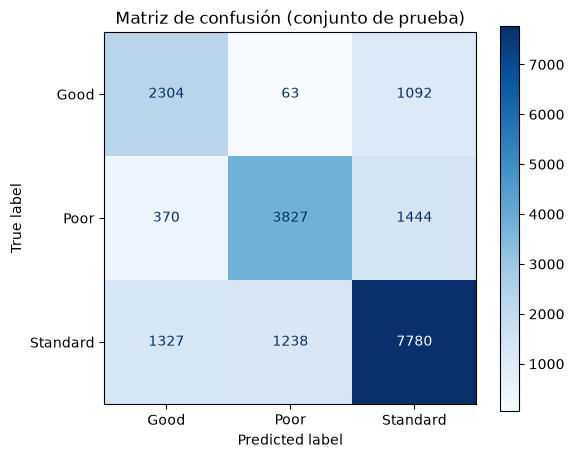

Top 10 variables más importantes:
Outstanding_Debt             0.3455
Credit_Mix_Standard          0.2000
Interest_Rate                0.0926
Payment_of_Min_Amount_Yes    0.0583
Changed_Credit_Limit         0.0512
Num_Credit_Card              0.0476
Credit_Mix__                 0.0456
Delay_from_due_date          0.0362
Total_EMI_per_month          0.0211
Num_Bank_Accounts            0.0142
dtype: float64


In [4]:
# Entrenamiento y evaluación del modelo
modelo_credit = analizar(X, y, guardar_matriz="../reports/figures/matriz_credit.png")